<a href="https://colab.research.google.com/github/2403a51078-code/AIDL_LAB_ASSIGNMENTS/blob/main/AIDL_lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First Five Rows
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Dataset Shape: (1338, 7)

Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

Missing Values
age         

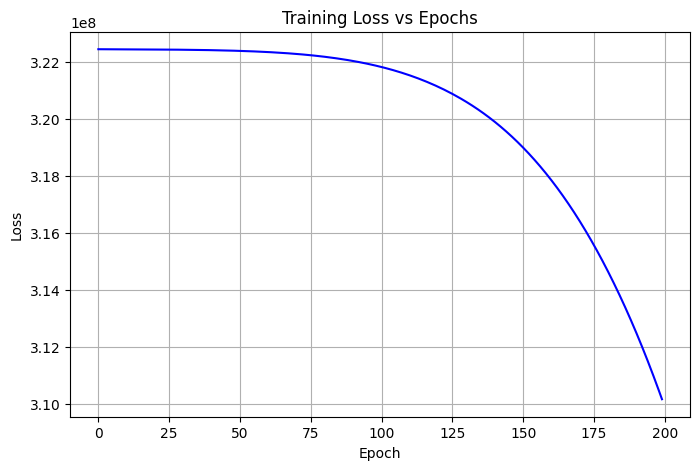

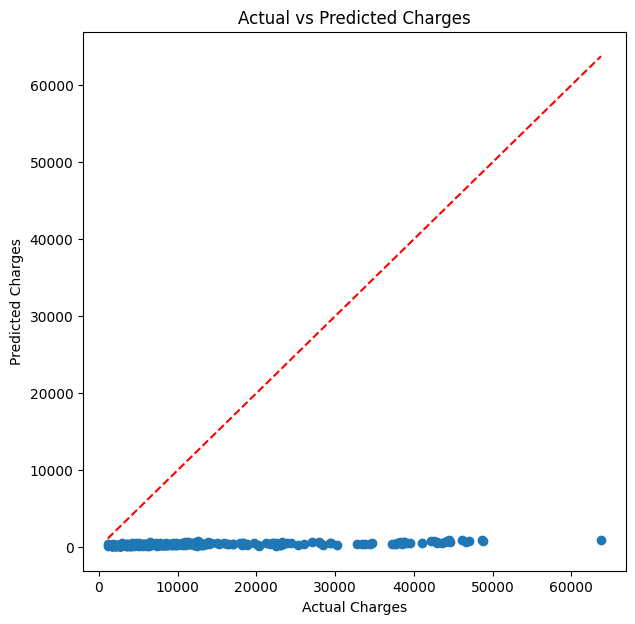

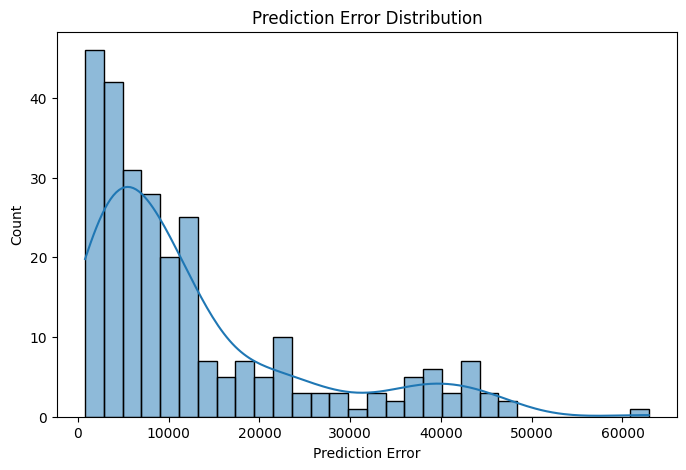

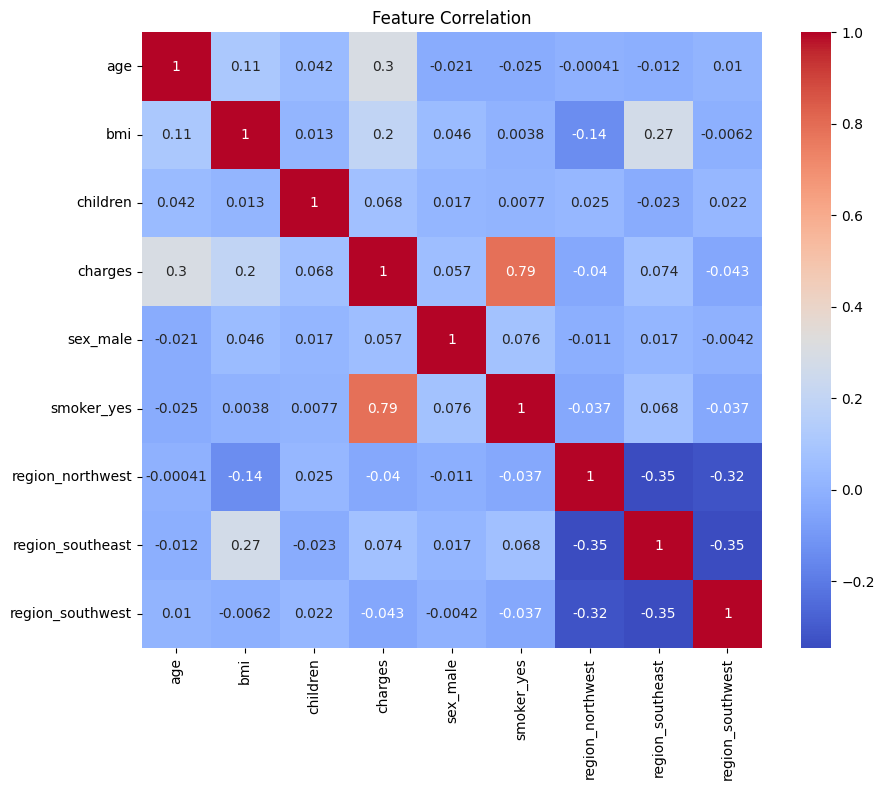


Sample Predictions

   Actual Charges  Predicted Charges
0     9095.068359         235.903046
1     5272.175781         251.668823
2    29330.982422         590.683899
3     9301.893555         376.978302
4    33750.292969         379.134918
5     4536.258789         471.994934
6     2117.338867         215.881195
7    14210.536133         509.538177
8     3732.625000         246.671860
9    10264.442383         407.930084

Conclusion


1. The insurance dataset was successfully loaded and preprocessed.

2. Categorical variables were converted using one-hot encoding.

3. Feature scaling was performed using StandardScaler.

4. A Feed Forward Neural Network was built using PyTorch.

5. The model was trained using the Adam optimizer and
   Mean Squared Error loss function.

6. The training loss decreased steadily during training,
   showing that the neural network successfully learned
   the relationship between the input features and insurance charges.

7. The Actual vs Predicted plot sh

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ============================================================
# Task 1: Load and Preprocess Dataset
# ============================================================

# Load dataset
df = pd.read_csv("/content/insurance.csv")

print("First Five Rows")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Information")
print(df.info())

print("\nMissing Values")
print(df.isnull().sum())

# ------------------------------------------------------------
# Convert categorical columns into numerical columns
# ------------------------------------------------------------

df = pd.get_dummies(df, drop_first=True)

print("\nColumns after Encoding")
print(df.columns)

# ------------------------------------------------------------
# Separate Features and Target
# ------------------------------------------------------------

X = df.drop("charges", axis=1)
y = df["charges"]

# ------------------------------------------------------------
# Feature Scaling
# ------------------------------------------------------------

scaler = StandardScaler()
X = scaler.fit_transform(X)

# ------------------------------------------------------------
# Train-Test Split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# ------------------------------------------------------------
# Convert to PyTorch Tensor
# ------------------------------------------------------------

X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

y_train = torch.FloatTensor(y_train.values).view(-1,1)
y_test = torch.FloatTensor(y_test.values).view(-1,1)

# ============================================================
# Task 2: Build PyTorch Model
# ============================================================

class InsuranceModel(nn.Module):

    def __init__(self, input_features):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_features,64),
            nn.ReLU(),

            nn.Linear(64,32),
            nn.ReLU(),

            nn.Linear(32,16),
            nn.ReLU(),

            nn.Linear(16,1)

        )

    def forward(self,x):
        return self.network(x)

model = InsuranceModel(X_train.shape[1])

print("\nModel Architecture\n")
print(model)

# ============================================================
# Loss Function and Optimizer
# ============================================================

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# ============================================================
# Task 3: Train Model
# ============================================================

epochs = 200

train_losses = []

for epoch in range(epochs):

    model.train()

    outputs = model(X_train)

    loss = criterion(outputs, y_train)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    if (epoch+1) % 20 == 0:

        print(f"Epoch [{epoch+1}/{epochs}]  Loss = {loss.item():.4f}")

# ============================================================
# Task 4: Evaluate Model
# ============================================================

model.eval()

with torch.no_grad():

    predictions = model(X_test)

predictions = predictions.numpy()

actual = y_test.numpy()

mse = mean_squared_error(actual, predictions)

mae = mean_absolute_error(actual, predictions)

rmse = np.sqrt(mse)

r2 = r2_score(actual, predictions)

print("\n==============================")
print("Evaluation Metrics")
print("==============================")

print("Mean Squared Error :", mse)
print("Mean Absolute Error:", mae)
print("Root Mean Squared Error:", rmse)
print("R2 Score:", r2)

# ============================================================
# Task 5: Visualization
# ============================================================

# -------------------------------
# Plot 1 : Training Loss
# -------------------------------

plt.figure(figsize=(8,5))

plt.plot(train_losses, color='blue')

plt.title("Training Loss vs Epochs")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.grid(True)

plt.show()

# -------------------------------
# Plot 2 : Actual vs Predicted
# -------------------------------

plt.figure(figsize=(7,7))

plt.scatter(actual, predictions)

plt.plot(
    [actual.min(), actual.max()],
    [actual.min(), actual.max()],
    'r--'
)

plt.xlabel("Actual Charges")

plt.ylabel("Predicted Charges")

plt.title("Actual vs Predicted Charges")

plt.show()

# -------------------------------
# Plot 3 : Error Distribution
# -------------------------------

errors = actual.flatten() - predictions.flatten()

plt.figure(figsize=(8,5))

sns.histplot(errors, bins=30, kde=True)

plt.title("Prediction Error Distribution")

plt.xlabel("Prediction Error")

plt.show()

# -------------------------------
# Plot 4 : Correlation Heatmap
# -------------------------------

plt.figure(figsize=(10,8))

sns.heatmap(df.corr(), annot=True, cmap="coolwarm")

plt.title("Feature Correlation")

plt.show()

# ============================================================
# Sample Predictions
# ============================================================

results = pd.DataFrame({

    "Actual Charges": actual.flatten(),

    "Predicted Charges": predictions.flatten()

})

print("\nSample Predictions\n")

print(results.head(10))

# ============================================================
# Task 6: Conclusion
# ============================================================

print("\n===================================================")
print("Conclusion")
print("===================================================")

print("""

1. The insurance dataset was successfully loaded and preprocessed.

2. Categorical variables were converted using one-hot encoding.

3. Feature scaling was performed using StandardScaler.

4. A Feed Forward Neural Network was built using PyTorch.

5. The model was trained using the Adam optimizer and
   Mean Squared Error loss function.

6. The training loss decreased steadily during training,
   showing that the neural network successfully learned
   the relationship between the input features and insurance charges.

7. The Actual vs Predicted plot shows how close the predictions
   are to the real values.

8. Evaluation metrics such as MSE, MAE, RMSE, and R² Score
   indicate the performance of the regression model.

Overall, the PyTorch model provides a good approach for
predicting medical insurance charges and demonstrates the
effectiveness of neural networks for regression problems.

""")